100%|██████████| 800/800 [00:03<00:00, 264.13it/s]


[np.float64(1.3674820402541068), np.float64(1.1683313385692145), np.float64(1.0868642911072022), np.float64(1.4045786434430114), np.float64(1.0614314805650966), np.float64(1.125597500898503), np.float64(1.358081897767547), np.float64(1.0158409229939032), np.float64(1.1916555336084502), np.float64(1.2285785315083941), np.float64(1.0206679547741844), np.float64(1.2936537600065898), np.float64(1.1907263671385826), np.float64(1.246675276012408), np.float64(1.7452594925626774), np.float64(2.004779622394151), np.float64(3.055409897489363), np.float64(4.601002501827188), np.float64(5.783087366563059), np.float64(7.335585533390667), np.float64(9.418272153007635), np.float64(10.362782673875113), np.float64(8.649827008158216), np.float64(5.042148638504805), np.float64(3.8820906142454468), np.float64(6.0439696473723545), np.float64(6.624396490913388), np.float64(9.634025003306643), np.float64(11.738005672499447), np.float64(12.592439215076324), np.float64(13.71516958602783), np.float64(8.44679106

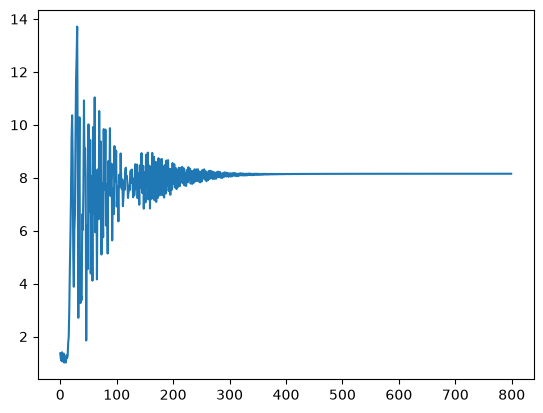

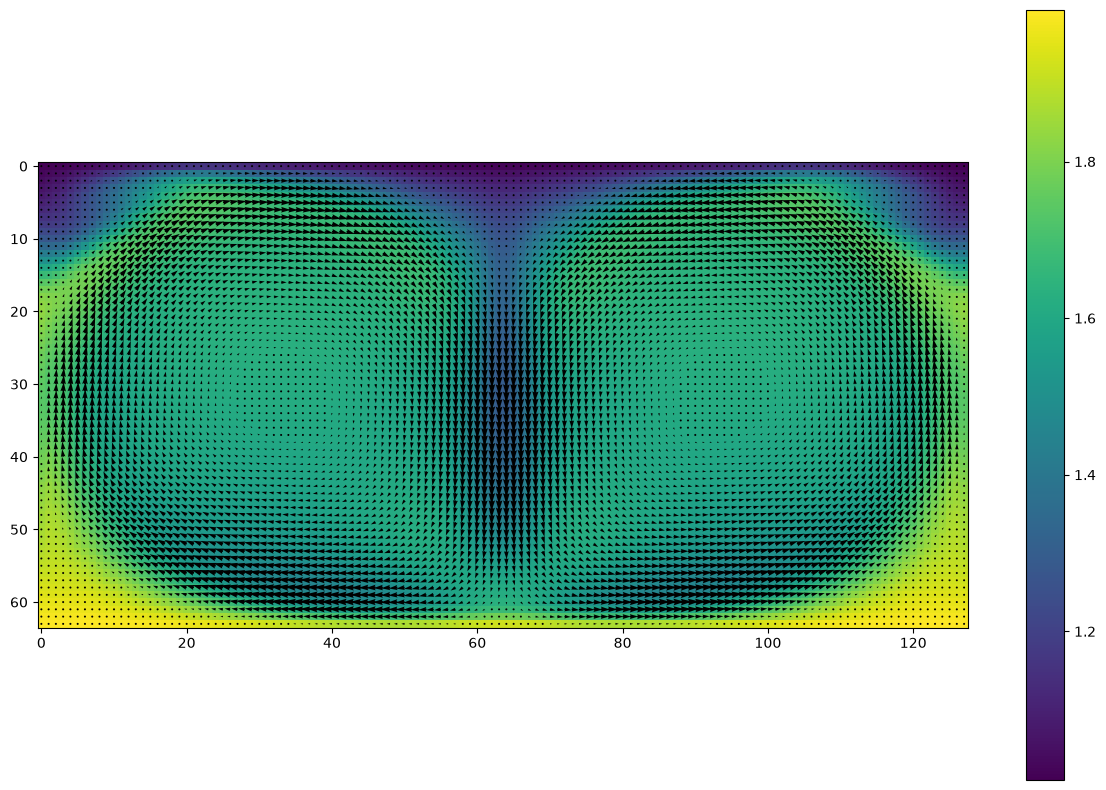

100%|██████████| 800/800 [00:10<00:00, 79.96it/s]


[np.float64(1.095013578119791), np.float64(1.1398662478390387), np.float64(1.0681800358245641), np.float64(1.056249078848626), np.float64(1.1149688326587601), np.float64(1.1013022119415141), np.float64(1.0448128086189472), np.float64(1.0782945332060834), np.float64(1.1202053330643216), np.float64(1.082351074146798), np.float64(1.0545108181994995), np.float64(1.1123877015937749), np.float64(1.1256955742840276), np.float64(1.087842966231388), np.float64(1.1465573445852795), np.float64(1.2599515396369265), np.float64(1.41523614058708), np.float64(1.7201027545271055), np.float64(2.4165014162423275), np.float64(3.4464068126291734), np.float64(4.766072565671613), np.float64(6.305948725862251), np.float64(8.061147597883137), np.float64(10.235877168008793), np.float64(12.499163001556207), np.float64(12.810286381360301), np.float64(9.992414980666343), np.float64(7.766957986039062), np.float64(7.828685656886063), np.float64(8.991693051019674), np.float64(9.045408690168886), np.float64(7.77877764

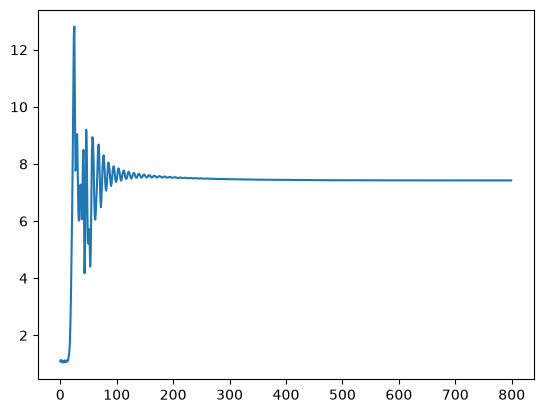

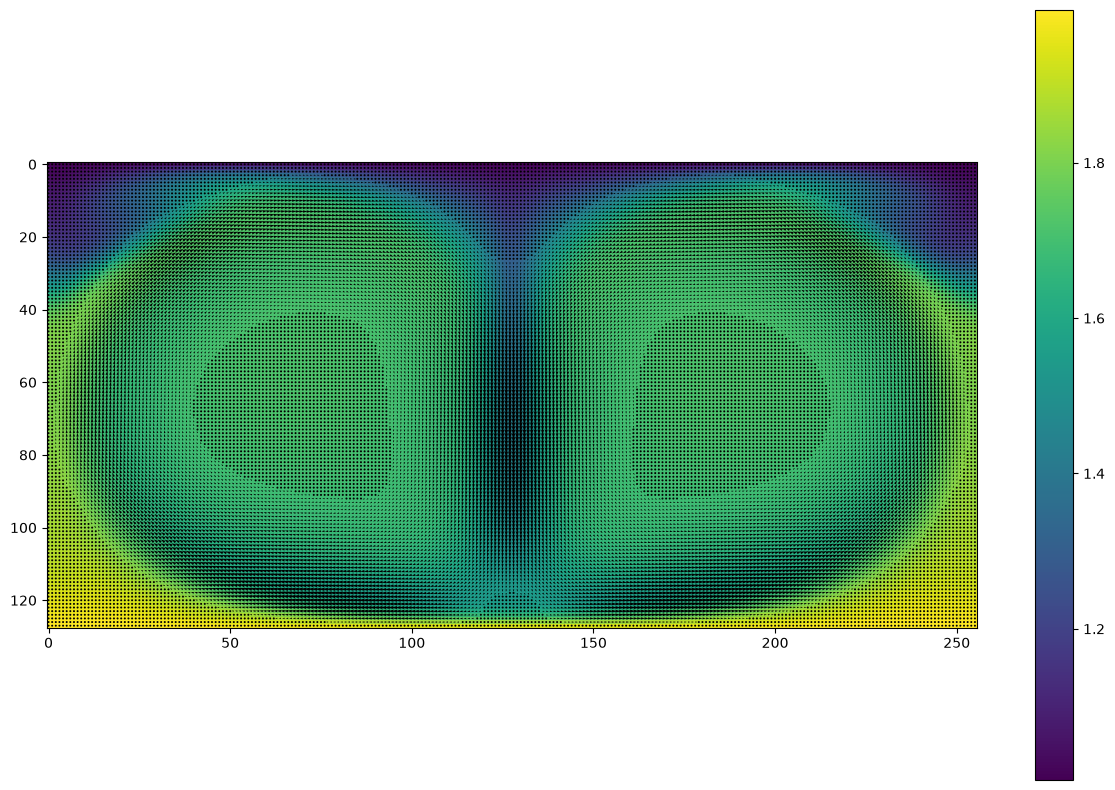

100%|██████████| 800/800 [01:29<00:00,  8.91it/s]

[np.float64(1.088731886317342), np.float64(1.062024208139726), np.float64(1.084787855766172), np.float64(1.0809821658364678), np.float64(1.0867388004494942), np.float64(1.1014836051358146), np.float64(1.0814183138904112), np.float64(1.0935673576189764), np.float64(1.0676390500781263), np.float64(1.111999761358015), np.float64(1.1093619443829683), np.float64(1.1290849325045689), np.float64(1.1374459523257956), np.float64(1.1486517298641334), np.float64(1.1945779580048779), np.float64(1.2575605033610877), np.float64(1.4807796130926594), np.float64(1.8964818571141453), np.float64(2.6968902983617298), np.float64(3.8422874462416914), np.float64(5.261944022061649), np.float64(6.912366733421148), np.float64(9.24424381298636), np.float64(12.077989706062274), np.float64(12.547897668318749), np.float64(11.21565512663553), np.float64(11.907884995642242), np.float64(14.410182629059094), np.float64(10.711807882829358), np.float64(4.606031950258375), np.float64(1.9380483809784144), np.float64(2.5644

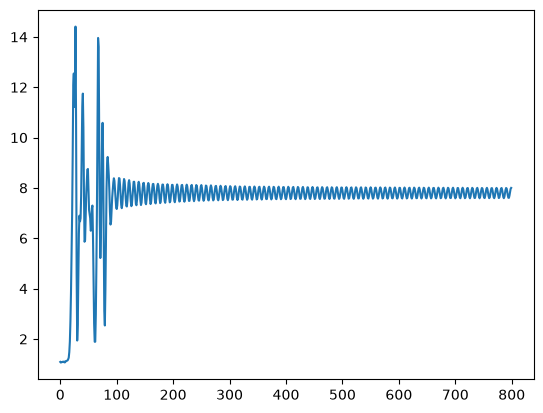

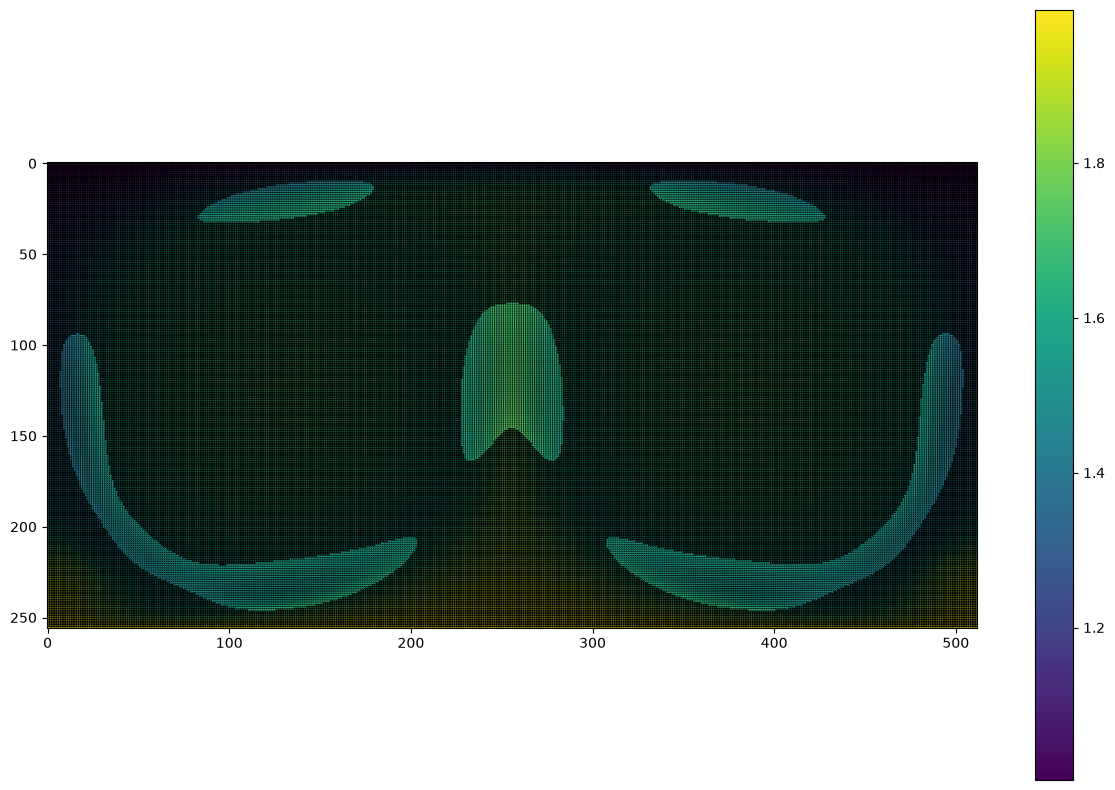

In [8]:
from controlRB import lbmd2q9
from matplotlib import pyplot as plt
from tqdm.auto import tqdm

scale = 0.5
for scale in [1.0, 2.0, 4.0]:
    lbm = lbmd2q9(
        mode="cuda",
        NX=int(scale*128),
        NY=int(scale*64),
        Ra=1e6,
        verbose=False,
    )

    n_steps = 800
    steps_per_frame = int(20*(scale/0.5)**2)
    nu_list = []
    for _ in tqdm(range(n_steps)):
        lbm.allsteps(nsteps=steps_per_frame)
        nu_list.append(lbm.calNuall()[0])
    plt.plot(nu_list)
    plt.show()
    lbm.flowtemplot()
    lbm.close()